# 02. NV2 — Phân nhóm hành vi chiếm dụng trạm sạc (Palo Alto, CA)

## Mục tiêu nghiên cứu (NV2) — Kết hợp phương pháp luận Khải & Thực nghiệm
Nhiệm vụ 2 tập trung giải quyết bài toán cốt lõi trong phân tích vận hành trạm sạc xe điện:
1. **3.2.1. Xây dựng không gian đặc trưng hành vi chiếm dụng**:
   - Kế thừa khung lý thuyết từ **Jonas et al. (2023)** (*Energies*) và **Bayram et al. (2023)** (*IEEE Access*) về việc bóc tách thời lượng sạc tích cực ($T_{charging}$), thời gian chiếm dụng nhàn rỗi ($T_{idle}$ / Overstay), và điện năng tiêu thụ ($E$).
   - **Kiểm định loại biến định lượng**: Kiểm chứng quan hệ hàm đại số giữa $Idle\ Ratio$ và các biến thời gian; thử nghiệm ảnh hưởng của giờ đến ($hour$ dạng chu kỳ sin/cos).
   - Đánh giá chiến lược chuẩn hóa: **Z-score Standardization** so với **Min-Max Scaling** đối với phân phối lệch phải.
2. **3.2.2. Lựa chọn thuật toán phân cụm: So sánh thực nghiệm K-Means và DBSCAN**:
   - Đánh giá K-Means trên lưới $k = 2 \dots 8$, đo lường tỷ lệ phần trăm suy giảm Inertia (Elbow) và các chỉ số nội tại (Silhouette, Davies-Bouldin, Calinski-Harabasz).
   - Đánh giá DBSCAN trên lưới 18 tổ hợp $(\epsilon, MinPts)$ và **kiểm định độ ổn định qua 5 random seeds** để chứng minh sự suy thoái cụm.
   - Huấn luyện mô hình chuẩn **K-Means ($k=4$)**, định danh 4 hồ sơ hành vi người dùng, đánh giá tỷ trọng thời gian chiếm dụng mạng lưới và kiểm định độ bền mô hình (Split-half & Time-window validation) qua các năm 2011–2020.

In [1]:
import sys
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Thiết lập hiển thị đồ thị chuyên nghiệp
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

# Các hằng số thực nghiệm
FEATS = ['charging_h', 'idle_h', 'kWh']          # 3 biến cốt lõi cho K-Means
RANDOM_STATE, N_INIT, N_SIL = 42, 10, 10000      # Cấu hình tính chỉ số nội tại

# Tự động phát hiện và nạp dữ liệu: ưu tiên Parquet đã tiền xử lý NV1, fallback CSV gốc
PARQUET_PATH = Path('../data/processed/sessions_features.parquet')
CSV_PATH = Path('../data/raw/EVChargingStationUsage.csv')

if PARQUET_PATH.exists():
    print(f"Nạp dữ liệu từ Parquet chuẩn hóa NV1: {PARQUET_PATH}")
    df = pd.read_parquet(PARQUET_PATH)
    valid = df[df['is_valid_session']].copy()
    valid['charging_h'] = valid['charging_time_hours']
    valid['idle_h'] = valid['idle_time_hours']
    valid['total_h'] = valid['total_duration_hours']
    valid['total_s'] = valid['total_duration_sec']
    valid['charging_s'] = valid['charging_time_sec']
    valid['Tidle'] = valid['idle_time_sec']
    valid['kWh'] = valid['Energy (kWh)']
    valid['yr'] = valid['start_year']
    valid['hour'] = valid['start_hour']
else:
    print(f"Nạp dữ liệu từ CSV thô: {CSV_PATH}")
    raw = pd.read_csv(CSV_PATH, low_memory=False, encoding='utf-8-sig')
    blank = raw['Transaction Date (Pacific Time)'].isna()
    df = raw.loc[~blank].copy()
    
    def secs(s):
        try:
            h, m, x = str(s).split(':')
            return int(h) * 3600 + int(m) * 60 + int(x)
        except Exception:
            return np.nan
            
    df['total_s'] = df['Total Duration (hh:mm:ss)'].map(secs)
    df['charging_s'] = df['Charging Time (hh:mm:ss)'].map(secs)
    df['Tidle'] = (df['total_s'] - df['charging_s']).clip(lower=0)
    df['kWh'] = pd.to_numeric(df['Energy (kWh)'], errors='coerce')
    tx = pd.to_datetime(df['Transaction Date (Pacific Time)'], errors='coerce')
    df['yr'] = tx.dt.year.astype(int)
    st = pd.to_datetime(df['Start Date'], errors='coerce')
    df['hour'] = st.dt.hour + st.dt.minute / 60.0
    
    valid = df.loc[(df.total_s > 0) & (df.charging_s > 0) & (df.kWh > 0)].copy()
    valid['charging_h'] = valid['charging_s'] / 3600
    valid['idle_h'] = valid['Tidle'] / 3600
    valid['total_h'] = valid['total_s'] / 3600
    valid['idle_ratio'] = valid['Tidle'] / valid['total_s']

print(f"-> SỐ PHIÊN HỢP LỆ ĐƯA VÀO PHÂN TÍCH: {len(valid):,} phiên")

Nạp dữ liệu từ Parquet chuẩn hóa NV1: ..\data\processed\sessions_features.parquet
-> SỐ PHIÊN HỢP LỆ ĐƯA VÀO PHÂN TÍCH: 259,356 phiên


---  
## 1. Khảo sát phân bố không gian đặc trưng hành vi chiếm dụng trạm sạc

=== BẢNG PHÂN VỊ CÁC BIẾN HÀNH VI CHIẾM DỤNG ===


,Thời gian sạc (h),Thời gian nhàn rỗi (h),Tỷ lệ nhàn rỗi,Năng lượng (kWh)
0.00,0.003,0.000,0.000,0.010
0.25,1.040,0.004,0.002,3.784
0.50,1.816,0.007,0.009,6.868
0.75,2.697,0.355,0.151,11.457
1.00,22.932,112.547,0.999,97.360



Giá trị trung bình:
charging_h    1.999
idle_h        0.488
idle_ratio    0.116
kWh           8.542


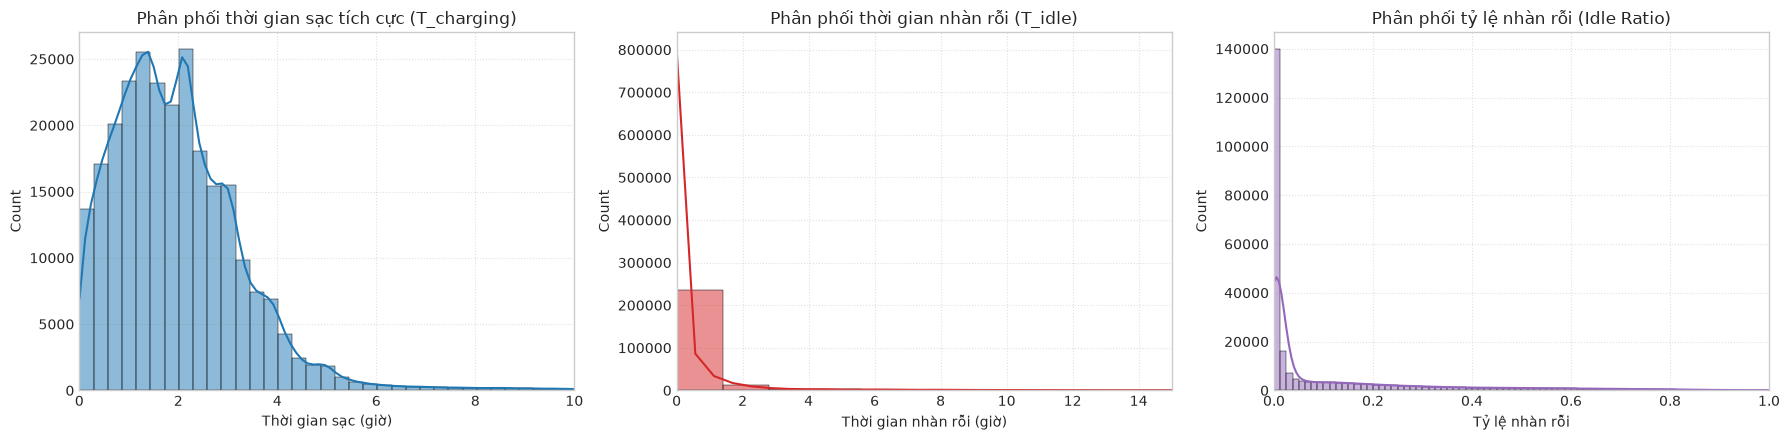

Nhận xét: 75% phiên có idle_ratio dưới 0.151; trung vị chỉ 0.009 (khoảng 32 giây) -> Phân bố lệch phải cực mạnh!


In [2]:
cols = ['charging_h', 'idle_h', 'idle_ratio', 'kWh']
q = valid[cols].quantile([0, .25, .5, .75, 1]).round(3)
q.columns = ['Thời gian sạc (h)', 'Thời gian nhàn rỗi (h)', 'Tỷ lệ nhàn rỗi', 'Năng lượng (kWh)']
print("=== BẢNG PHÂN VỊ CÁC BIẾN HÀNH VI CHIẾM DỤNG ===")
display(q)

print("\nGiá trị trung bình:")
print(valid[cols].mean().round(3).to_string())

# Trực quan hóa phân phối
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(valid['charging_h'], bins=80, ax=axes[0], color='#1f77b4', kde=True)
axes[0].set(title='Phân phối thời gian sạc tích cực (T_charging)', xlabel='Thời gian sạc (giờ)', xlim=(0, 10))
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.histplot(valid['idle_h'], bins=80, ax=axes[1], color='#d62728', kde=True)
axes[1].set(title='Phân phối thời gian nhàn rỗi (T_idle)', xlabel='Thời gian nhàn rỗi (giờ)', xlim=(0, 15))
axes[1].grid(True, linestyle=':', alpha=0.6)

sns.histplot(valid['idle_ratio'], bins=80, ax=axes[2], color='#9467bd', kde=True)
axes[2].set(title='Phân phối tỷ lệ nhàn rỗi (Idle Ratio)', xlabel='Tỷ lệ nhàn rỗi', xlim=(0, 1))
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print("Nhận xét: 75% phiên có idle_ratio dưới 0.151; trung vị chỉ 0.009 (khoảng 32 giây) -> Phân bố lệch phải cực mạnh!")

---  
## 2. Kiểm chứng tương quan đại số, kiểm định loại biến & so sánh chuẩn hóa

### Kiểm chứng quan hệ hàm đại số của $Idle\ Ratio$
Ta kiểm tra quan hệ lý thuyết: $Idle\ Ratio = \frac{T_{idle}}{T_{idle} + T_{charging}}$.
Nếu sai lệch bằng 0, việc đưa cả 3 biến vào hàm khoảng cách Euclid sẽ gây thừa thông tin và đa cộng tuyến hình học.

In [3]:
print(f"TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = {len(valid):,}):")
display(valid[cols].corr().round(3))

rec = valid['idle_h'] / (valid['idle_h'] + valid['charging_h'])
diff_max = (rec - valid['idle_ratio']).abs().max()
print(f"\nKiểm chứng: idle_ratio = T_idle / (T_idle + T_charging)")
print(f"  Sai lệch tuyệt đối lớn nhất = {diff_max:.2e} -> Đây là QUAN HỆ ĐẠI SỐ TUYỆT ĐỐI, không đơn thuần là tương quan!")

# Kiểm định 4 kịch bản lựa chọn biến (A, B, C, D)
valid['hs'] = np.sin(2 * np.pi * valid['hour'] / 24)
valid['hc'] = np.cos(2 * np.pi * valid['hour'] / 24)
valid['idle_cap'] = valid['idle_h'].clip(upper=24)

np.random.seed(0)
ms = np.random.choice(len(valid), N_SIL, replace=False)

print(f"\nKIỂM ĐỊNH LOẠI BIẾN (k = 4, Z-score, mẫu {N_SIL:,} phiên):")
TESTS = [
    ('A. Bỏ giờ đến (3 biến cốt lõi, ĐƯỢC CHỌN)', FEATS, 'idle_h'),
    ('B. Thêm giờ đến chu kỳ (5 biến)', FEATS + ['hs', 'hc'], 'idle_h'),
    ('C. Kẹp giờ nhàn rỗi tại 24h', FEATS, 'idle_cap'),
    ('D. Thay giờ nhàn rỗi bằng tỷ lệ', ['charging_h', 'idle_ratio', 'kWh'], 'idle_h')
]
for name, f_list, idle_col in TESTS:
    data = valid[f_list].copy()
    if idle_col != 'idle_h':
        data['idle_h'] = valid[idle_col]
    Z = StandardScaler().fit_transform(data.to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    print(f"  {name:<40} sil={silhouette_score(Z[ms], lab[ms]):.3f} db={davies_bouldin_score(Z[ms], lab[ms]):.3f} ch={calinski_harabasz_score(Z[ms], lab[ms]):.0f}")

print("\nSO SÁNH CHUẨN HÓA: Z-score vs Min-Max (k = 4):")
for nm, sc in [('Z-score  ', StandardScaler()), ('Min-Max  ', MinMaxScaler())]:
    Z = sc.fit_transform(valid[FEATS].to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    print(f"  {nm} sil={silhouette_score(Z[ms], lab[ms]):.3f} db={davies_bouldin_score(Z[ms], lab[ms]):.3f} sizes={sorted(np.bincount(lab).tolist(), reverse=True)}")

hi = valid['idle_h'].max()
print(f"  Tỷ lệ phân tử qua trung vị trên trục idle_h:")
print(f"    Min-Max : 99% phiên nằm dưới {100 * valid.idle_h.quantile(.99) / hi:.3f}% của đoạn [0, 1] (bị dồn cục ngoại vi)")
print(f"    Z-score : 99% phiên nằm dưới {(valid.idle_h.quantile(.99) - valid.idle_h.mean()) / valid.idle_h.std():.2f} độ lệch chuẩn (phân phối đều đặn hơn)")

TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = 259,356):


,charging_h,idle_h,idle_ratio,kWh
charging_h,1.000,0.196,-0.012,0.872
idle_h,0.196,1.000,0.700,0.148
idle_ratio,-0.012,0.700,1.000,-0.056
kWh,0.872,0.148,-0.056,1.000



Kiểm chứng: idle_ratio = T_idle / (T_idle + T_charging)
  Sai lệch tuyệt đối lớn nhất = 1.11e-16 -> Đây là QUAN HỆ ĐẠI SỐ TUYỆT ĐỐI, không đơn thuần là tương quan!

KIỂM ĐỊNH LOẠI BIẾN (k = 4, Z-score, mẫu 10,000 phiên):
  A. Bỏ giờ đến (3 biến cốt lõi, ĐƯỢC CHỌN) sil=0.469 db=0.752 ch=7457
  B. Thêm giờ đến chu kỳ (5 biến)          sil=0.331 db=1.082 ch=3860
  C. Kẹp giờ nhàn rỗi tại 24h              sil=0.467 db=0.753 ch=7711
  D. Thay giờ nhàn rỗi bằng tỷ lệ          sil=0.445 db=0.757 ch=7619

SO SÁNH CHUẨN HÓA: Z-score vs Min-Max (k = 4):
  Z-score   sil=0.469 db=0.752 sizes=[155576, 91112, 6913, 5755]
  Min-Max   sil=0.445 db=0.738 sizes=[103555, 102402, 48901, 4498]
  Tỷ lệ phân tử qua trung vị trên trục idle_h:
    Min-Max : 99% phiên nằm dưới 6.899% của đoạn [0, 1] (bị dồn cục ngoại vi)
    Z-score : 99% phiên nằm dưới 4.92 độ lệch chuẩn (phân phối đều đặn hơn)


---  
## 3. Khảo sát số cụm tối ưu K-Means ($k = 2 \dots 8$) & Tỷ lệ giảm Inertia

QUÉT SỐ CỤM k TRÊN TOÀN BỘ 259,356 PHIÊN SẠC:
  k=2 inertia=   502781 sil=0.486 db=1.019 ch=5567 sizes=[188101, 71255]
  k=3 inertia=   351072 sil=0.487 db=0.782 ch=6518 sizes=[177308, 74650, 7398]
  k=4 inertia=   248489 sil=0.469 db=0.752 ch=7457 sizes=[155576, 91112, 6913, 5755]
  k=5 inertia=   201879 sil=0.396 db=0.806 ch=7485 sizes=[104091, 99998, 44495, 6830, 3942]
  k=6 inertia=   180673 sil=0.375 db=0.866 ch=6988 sizes=[89948, 89302, 57925, 12721, 6755, 2705]
  k=7 inertia=   160159 sil=0.379 db=0.894 ch=6979 sizes=[88613, 87523, 57799, 13117, 6810, 2781, 2713]
  k=8 inertia=   139285 sil=0.390 db=0.833 ch=6899 sizes=[85222, 84907, 56665, 12896, 11526, 5412, 2723, 5]

TỶ LỆ GIẢM INERTIA GIỮA CÁC BƯỚC k (ELBOW RATE):
  k=2 -> k=3 : -30.2%
  k=3 -> k=4 : -29.2%
  k=4 -> k=5 : -18.8%
  k=5 -> k=6 : -10.5%
  k=6 -> k=7 : -11.4%
  k=7 -> k=8 : -13.0%


C:\Users\Elior\AppData\Local\Temp\ipykernel_17636\3544261587.py:18: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  plt.plot(list(inertia.keys()), list(inertia.values()), 'bo-', linewidth=2, markersize=8, color='#1f77b4')


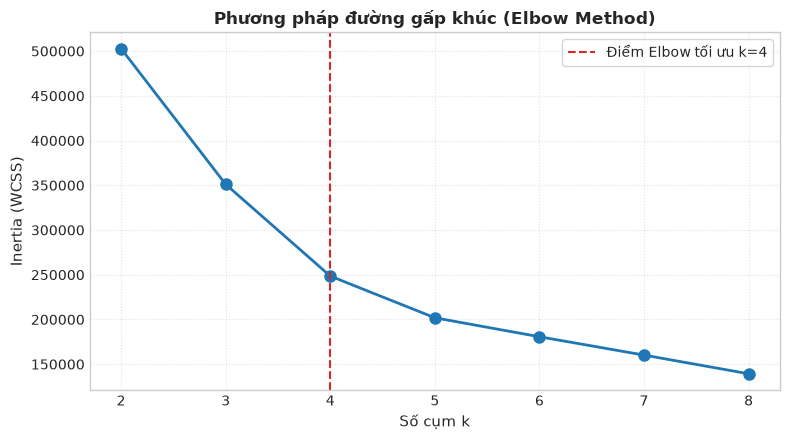

In [4]:
print(f"QUÉT SỐ CỤM k TRÊN TOÀN BỘ {len(valid):,} PHIÊN SẠC:")
Z = StandardScaler().fit_transform(valid[FEATS].to_numpy())
inertia = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    lab = km.labels_
    inertia[k] = km.inertia_
    idx = ms if len(Z) > N_SIL else np.arange(len(Z))
    print(f"  k={k} inertia={km.inertia_:9.0f} sil={silhouette_score(Z[idx], lab[idx]):.3f} db={davies_bouldin_score(Z[idx], lab[idx]):.3f} ch={calinski_harabasz_score(Z[idx], lab[idx]):.0f} sizes={sorted(np.bincount(lab).tolist(), reverse=True)}")

print("\nTỶ LỆ GIẢM INERTIA GIỮA CÁC BƯỚC k (ELBOW RATE):")
for k in range(2, 8):
    pct_drop = 100 * (1 - inertia[k + 1] / inertia[k])
    print(f"  k={k} -> k={k+1} : -{pct_drop:.1f}%")

# Đồ thị Elbow
plt.figure(figsize=(8, 4.5))
plt.plot(list(inertia.keys()), list(inertia.values()), 'bo-', linewidth=2, markersize=8, color='#1f77b4')
plt.axvline(x=4, color='#d62728', linestyle='--', label='Điểm Elbow tối ưu k=4')
plt.xticks(list(inertia.keys()))
plt.xlabel('Số cụm k', fontsize=11)
plt.ylabel('Inertia (WCSS)', fontsize=11)
plt.title('Phương pháp đường gấp khúc (Elbow Method)', fontsize=12, fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

---  
## 4. Thực nghiệm DBSCAN & Bằng chứng thực nghiệm về tính bất ổn định

Ta tiến hành thử nghiệm DBSCAN trên mẫu 10.000 phiên với lưới 18 tổ hợp tham số, sau đó chạy lại trên 5 random seed khác nhau.

In [5]:
print(f"DBSCAN TRÊN MẪU {N_SIL:,} PHIÊN (độ phức tạp O(n^2) không khả thi trên toàn bộ tập):")
Zs = StandardScaler().fit_transform(valid[FEATS].to_numpy())[ms]
res = []
for eps, mp in itertools.product([0.5, 0.6, 0.7, 0.8, 0.9, 1.0], [10, 20, 50]):
    lab = DBSCAN(eps=eps, min_samples=mp).fit(Zs).labels_
    nc = len(set(lab)) - (-1 in set(lab))
    noise = 100 * (lab == -1).mean()
    res.append((eps, mp, nc, noise))
    print(f"  eps={eps:.1f} min_samples={mp:2d} -> số cụm={nc}, tỷ lệ nhiễu={noise:.1f}%")

print(f"\nTóm tắt: số cụm dao động {min(r[2] for r in res)}-{max(r[2] for r in res)}, nhiễu {min(r[3] for r in res):.1f}%-{max(r[3] for r in res):.1f}%")
print(f"  Số tổ hợp trả về đúng 1 siêu cụm (hiệu ứng chuỗi): {sum(r[2] == 1 for r in res)}/18 tổ hợp")
print(f"  Tổ hợp cho 4 cụm: {[(r[0], r[1], round(r[3], 1)) for r in res if r[2] == 4]}")

print("\nKIỂM TRA ĐỘ ỔN ĐỊNH CỦA DBSCAN 4 CỤM QUA 5 RANDOM SEEDS KHÁC NHAU:")
for seed in [0, 1, 2, 7, 42]:
    m2 = np.random.default_rng(seed).choice(len(valid), N_SIL, replace=False)
    Z2 = StandardScaler().fit_transform(valid[FEATS].to_numpy())[m2]
    lab = DBSCAN(eps=0.5, min_samples=10).fit(Z2).labels_
    nc = len(set(lab)) - (-1 in set(lab))
    print(f"  seed={seed:2d} (eps=0.5, min_samples=10) -> số cụm={nc}, tỷ lệ nhiễu={100 * (lab == -1).mean():.1f}%")

print("\nKẾT LUẬN THỰC NGHIỆM: DBSCAN cực kỳ bất ổn định trên các mẫu con khác nhau (số cụm dao động từ 2 đến 5 cụm). Do đó loại bỏ DBSCAN!")

DBSCAN TRÊN MẪU 10,000 PHIÊN (độ phức tạp O(n^2) không khả thi trên toàn bộ tập):
  eps=0.5 min_samples=10 -> số cụm=4, tỷ lệ nhiễu=2.6%
  eps=0.5 min_samples=20 -> số cụm=2, tỷ lệ nhiễu=4.4%
  eps=0.5 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=6.0%
  eps=0.6 min_samples=10 -> số cụm=3, tỷ lệ nhiễu=1.8%
  eps=0.6 min_samples=20 -> số cụm=2, tỷ lệ nhiễu=3.1%
  eps=0.6 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=5.2%
  eps=0.7 min_samples=10 -> số cụm=1, tỷ lệ nhiễu=1.3%
  eps=0.7 min_samples=20 -> số cụm=1, tỷ lệ nhiễu=2.4%
  eps=0.7 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=4.4%
  eps=0.8 min_samples=10 -> số cụm=1, tỷ lệ nhiễu=1.1%
  eps=0.8 min_samples=20 -> số cụm=1, tỷ lệ nhiễu=1.7%
  eps=0.8 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=3.6%
  eps=0.9 min_samples=10 -> số cụm=1, tỷ lệ nhiễu=1.0%
  eps=0.9 min_samples=20 -> số cụm=1, tỷ lệ nhiễu=1.3%
  eps=0.9 min_samples=50 -> số cụm=1, tỷ lệ nhiễu=2.9%
  eps=1.0 min_samples=10 -> số cụm=2, tỷ lệ nhiễu=0.7%
  eps=1.0 min_samples=20 -> số cụm=1, 

---  
## 5. Mô hình chuẩn K-Means ($k = 4$) & Hồ sơ 4 cụm hành vi người dùng

In [6]:
K = 4
scaler = StandardScaler().fit(valid[FEATS].to_numpy())
Z = scaler.transform(valid[FEATS].to_numpy())
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
valid['cluster'] = km.labels_

prof = valid.groupby('cluster').agg(
    so_phien=('cluster', 'size'),
    ti_le=('cluster', lambda s: 100 * len(s) / len(valid)),
    ti_le_thoi_gian=('total_s', lambda s: 100 * s.sum() / valid['total_s'].sum()),
    tg_sac=('charging_h', 'mean'), tg_sac_trung_vi=('charging_h', 'median'),
    tg_nhan_roi=('idle_h', 'mean'), tg_nhan_roi_trung_vi=('idle_h', 'median'),
    idle_ratio=('idle_ratio', 'mean'), nang_luong=('kWh', 'mean'),
    nang_luong_trung_vi=('kWh', 'median'),
    gio_den=('hour', 'mean'), gio_den_trung_vi=('hour', 'median'),
    phien_idle_gt3h=('idle_h', lambda s: 100 * (s > 3).mean())).round(3)

print(f"=== HỒ SƠ 4 CỤM HÀNH VI CHIẾM DỤNG (K = {K}, TOÀN BỘ {len(valid):,} PHIÊN) ===")
display(prof)

print("\nTỶ TRỌNG TỔNG THỜI GIAN KẾT NỐI MẠNG LƯỚI THEO CỤM:")
display(prof['ti_le_thoi_gian'].round(2))

print("\nPHÂN BỐ GIỜ ĐẾN THEO CỤM (Phân vị 10% / 50% / 90%):")
display(valid.groupby('cluster')['hour'].describe(percentiles=[.1, .5, .9]).round(1)[['count', 'mean', '10%', '50%', '90%']])

=== HỒ SƠ 4 CỤM HÀNH VI CHIẾM DỤNG (K = 4, TOÀN BỘ 259,356 PHIÊN) ===


,so_phien,ti_le,ti_le_thoi_gian,tg_sac,tg_sac_trung_vi,tg_nhan_roi,tg_nhan_roi_trung_vi,idle_ratio,nang_luong,nang_luong_trung_vi,gio_den,gio_den_trung_vi,phien_idle_gt3h
cluster,,,,,,,,,,,,,
0,155576,59.986,34.991,1.187,1.196,0.264,0.006,0.117,4.569,4.562,13.450,17.0,0.805
1,5755,2.219,7.085,6.982,6.288,0.959,0.026,0.093,38.325,35.176,12.449,15.0,12.389
2,91112,35.130,46.239,2.968,2.862,0.306,0.008,0.073,13.059,12.264,14.421,17.0,1.038
3,6913,2.665,11.684,3.350,3.479,7.552,6.790,0.682,13.628,12.274,7.335,5.0,100.000



TỶ TRỌNG TỔNG THỜI GIAN KẾT NỐI MẠNG LƯỚI THEO CỤM:


cluster
0    34.99
1     7.08
2    46.24
3    11.68
Name: ti_le_thoi_gian, dtype: float64


PHÂN BỐ GIỜ ĐẾN THEO CỤM (Phân vị 10% / 50% / 90%):


,count,mean,10%,50%,90%
cluster,,,,,
0,155576.0,13.4,1.0,17.0,22.0
1,5755.0,12.4,2.0,15.0,21.0
2,91112.0,14.4,1.0,17.0,22.0
3,6913.0,7.3,2.0,5.0,18.0


---  
## 6. Kiểm định tính vững chắc (Robustness & Temporal Stability)

### 6.1. Split-half validation (Huấn luyện trên 1/2 dữ liệu ngẫu nhiên)
Kiểm tra xem mô hình K-Means có bị nhạy cảm khi giảm một nửa cỡ mẫu hay không.

In [7]:
rng = np.random.default_rng(1)
idx = rng.permutation(len(valid))
half = valid.iloc[idx[:len(valid) // 2]].copy()
k1 = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(
    StandardScaler().fit_transform(half[FEATS].to_numpy()))
half['h'] = k1.labels_

print(f"ĐỘ ỔN ĐỊNH: Huấn luyện trên 1/2 dữ liệu ({len(half):,} phiên):")
display(half.groupby('h')[FEATS + ['idle_ratio']].mean().round(3))
print("Số phiên theo từng cụm trên 1/2 mẫu:")
print(half.groupby('h').size().to_string())
print("-> Nhận xét: Tâm cụm và tỷ lệ phân bố giữa 2 nửa mẫu khớp nhau gần như tuyệt đối!")

ĐỘ ỔN ĐỊNH: Huấn luyện trên 1/2 dữ liệu (129,678 phiên):


,charging_h,idle_h,kWh,idle_ratio
h,,,,
0,1.186,0.259,4.560,0.115
1,6.953,0.953,38.051,0.093
2,3.311,7.493,13.449,0.683
3,2.961,0.303,13.007,0.073


Số phiên theo từng cụm trên 1/2 mẫu:
h
0    77588
1     2910
2     3510
3    45670
-> Nhận xét: Tâm cụm và tỷ lệ phân bố giữa 2 nửa mẫu khớp nhau gần như tuyệt đối!


### 6.2. Kiểm định độ ổn định theo cửa sổ thời gian (2011–2020) & Tác động chính sách
Huấn luyện $k=4$ độc lập cho từng giai đoạn và đo lường sự dịch chuyển của hành vi chiếm dụng nghiêm trọng.

ĐỘ ỔN ĐỊNH THEO CỬA SỔ THỜI GIAN: k = 4 riêng cho từng giai đoạn:
 2011-2016 (99,692 phiên):  roi 0.30h/r 0.13/4.1 kWh (56%) | roi 0.38h/r 0.09/11.9 kWh (39%) | roi 1.46h/r 0.13/41.2 kWh (1%) | roi 7.34h/r 0.68/13.2 kWh (4%)
 2017-2017 (49,024 phiên):  roi 0.30h/r 0.13/4.6 kWh (57%) | roi 0.32h/r 0.08/12.9 kWh (38%) | roi 1.37h/r 0.13/36.7 kWh (2%) | roi 7.65h/r 0.69/13.3 kWh (3%)
 2018-2018 (42,798 phiên):  roi 0.25h/r 0.06/13.2 kWh (34%) | roi 0.26h/r 0.11/4.8 kWh (63%) | roi 0.79h/r 0.08/39.6 kWh (2%) | roi 7.83h/r 0.68/16.1 kWh (1%)
 2019-2019 (47,728 phiên):  roi 0.22h/r 0.10/5.0 kWh (65%) | roi 0.32h/r 0.06/14.7 kWh (32%) | roi 1.35h/r 0.11/38.0 kWh (3%) | roi 112.49h/r 0.99/3.6 kWh (0%)
 2020-2020 (20,109 phiên):  roi 0.16h/r 0.08/4.8 kWh (64%) | roi 0.23h/r 0.05/15.5 kWh (30%) | roi 0.46h/r 0.05/37.1 kWh (5%) | roi 9.72h/r 0.67/23.0 kWh (1%)

TỶ LỆ PHIÊN CÓ MỨC CHIẾM DỤNG NGHIÊM TRỌNG (Idle Ratio > 50%) THEO NĂM:


yr
2011    11.70
2012    10.76
2013     8.03
2014     7.42
2015     9.54
2016    10.93
2017     8.83
2018     5.59
2019     4.40
2020     3.45
Name: hi, dtype: float64

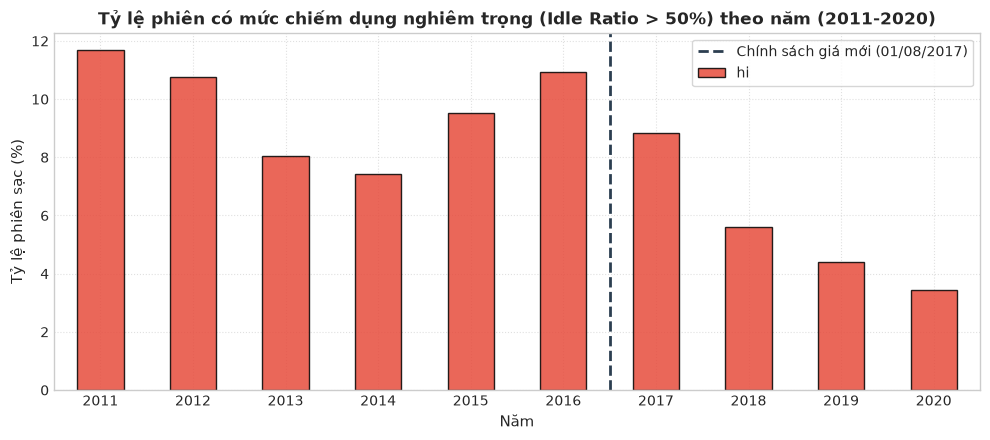

In [9]:
print("ĐỘ ỔN ĐỊNH THEO CỬA SỔ THỜI GIAN: k = 4 riêng cho từng giai đoạn:")
for a, b in [(2011, 2016), (2017, 2017), (2018, 2018), (2019, 2019), (2020, 2020)]:
    w = valid[(valid.yr >= a) & (valid.yr <= b)]
    Zw = StandardScaler().fit_transform(w[FEATS].to_numpy())
    lab = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zw).labels_
    p = w.assign(c=lab).groupby('c').agg(
        n=('c', 'size'), sac=('charging_h', 'mean'),
        roi=('idle_h', 'mean'), r=('idle_ratio', 'mean'),
        en=('kWh', 'mean'), gio=('hour', 'median')).round(2).sort_values('roi')
    print(f" {a}-{b} ({len(w):,} phiên): ", ' | '.join(
        'roi %.2fh/r %.2f/%.1f kWh (%.0f%%)' % (r.roi, r.r, r.en, 100 * r.n / len(w))
        for _, r in p.iterrows()))

# Xu hướng phiên có idle_ratio > 0.5 theo năm
print("\nTỶ LỆ PHIÊN CÓ MỨC CHIẾM DỤNG NGHIÊM TRỌNG (Idle Ratio > 50%) THEO NĂM:")
hi_trend = valid.assign(hi=valid.idle_ratio > .5).groupby('yr')['hi'].mean().mul(100).loc[2011:2020].round(2)
display(hi_trend)

# Đồ thị xu hướng giảm của hành vi chiếm dụng
plt.figure(figsize=(10, 4.5))
hi_trend.plot(kind='bar', color='#e74c3c', edgecolor='black', alpha=0.85)
plt.axvline(x=5.5, color='#2c3e50', linestyle='--', linewidth=2, label='Chính sách giá mới (01/08/2017)')
plt.title('Tỷ lệ phiên có mức chiếm dụng nghiêm trọng (Idle Ratio > 50%) theo năm (2011-2020)', fontweight='bold')
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Tỷ lệ phiên sạc (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
